In [6]:
from sklearn.feature_extraction.text import CountVectorizer
import re
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [7]:
# Зчитування та попередня обробка корпусу

stoplist = stopwords.words('english')
lk = ['n', 'v', 'a', 'r', 's']

def lemmatize_text(text):
    lemmatizer = WordNetLemmatizer()
    words = word_tokenize(text)
    pos_tagged = nltk.pos_tag(words)
    lemmatized_words = []

    for i, word in enumerate(words):
        word_pos = pos_tagged[i][1].lower() if pos_tagged[i][1].lower() in lk else 'n'
        lemmatized_words.append(lemmatizer.lemmatize(word.lower(), pos=word_pos))
    
    return " ".join(lemmatized_words)

# Зчитування
text_file = open("doc9.txt", "r", encoding="utf-8")
corpus = []

for line in text_file:
    # Видалення зайвих символів 
    line = re.sub(r'[^\w\s\'’-]', '', line.strip())
    line = re.sub(r'\d+', ' ', line)
    line = re.sub(r'\s+', ' ', line).strip()
    
    # Видалення стоп-слів
    clean_line = " ".join([word for word in line.split() if word.lower() not in stoplist])

    # Лематизація
    line = lemmatize_text(clean_line)
    
    corpus.append(line)

corpus

['name cuicul city built metre sea level',
 'thaw crab frozencut serving-size piece crack',
 'city initially populated colony roman soldier italy eventually grew become large trading market',
 'arrange crab vegetable large platter serving bowl',
 'looking email address world health organization',
 'cooking broth may ladled cup served soup crab vegetable cooked']

In [8]:
# Сумка слів
cv = CountVectorizer(min_df=0., max_df=1.)
cv_matrix = cv.fit_transform(corpus)
feature_names = cv.get_feature_names_out()
bow_df = pd.DataFrame(cv_matrix.toarray(), columns=feature_names)
print(feature_names)

['address' 'arrange' 'become' 'bowl' 'broth' 'built' 'city' 'colony'
 'cooked' 'cooking' 'crab' 'crack' 'cuicul' 'cup' 'email' 'eventually'
 'frozencut' 'grew' 'health' 'initially' 'italy' 'ladled' 'large' 'level'
 'looking' 'market' 'may' 'metre' 'name' 'organization' 'piece' 'platter'
 'populated' 'roman' 'sea' 'served' 'serving' 'size' 'soldier' 'soup'
 'thaw' 'trading' 'vegetable' 'world']


In [9]:
# Вектор слова crab
crab_vector = cv_matrix[:, cv.vocabulary_['crab']].toarray()
print(crab_vector)

[[0]
 [1]
 [0]
 [1]
 [0]
 [1]]


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np

In [11]:
# TF-IDF
tv = TfidfVectorizer(min_df=0., max_df=1.)
tv_matrix = tv.fit_transform(corpus).toarray()
tfidf_df = pd.DataFrame(np.round(tv_matrix, 2), columns=tv.get_feature_names_out())
tfidf_df

,address,arrange,become,bowl,broth,built,city,colony,cooked,cooking,...,sea,served,serving,size,soldier,soup,thaw,trading,vegetable,world
0,0.00,0.00,0.00,0.00,0.00,0.39,0.32,0.00,0.00,0.00,...,0.39,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.33,0.4,0.00,0.00,0.4,0.00,0.00,0.00
2,0.00,0.00,0.28,0.00,0.00,0.00,0.23,0.28,0.00,0.00,...,0.00,0.00,0.00,0.0,0.28,0.00,0.0,0.28,0.00,0.00
3,0.00,0.43,0.00,0.43,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.35,0.0,0.00,0.00,0.0,0.00,0.35,0.00
4,0.41,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.41
5,0.00,0.00,0.00,0.00,0.33,0.00,0.00,0.00,0.33,0.33,...,0.00,0.33,0.00,0.0,0.00,0.33,0.0,0.00,0.27,0.00


In [12]:
# Ієрархічна агломераційна кластеризація
ag = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
ag.fit(tv_matrix)
ag.labels_

array([0, 1, 0, 1, 2, 1], dtype=int64)

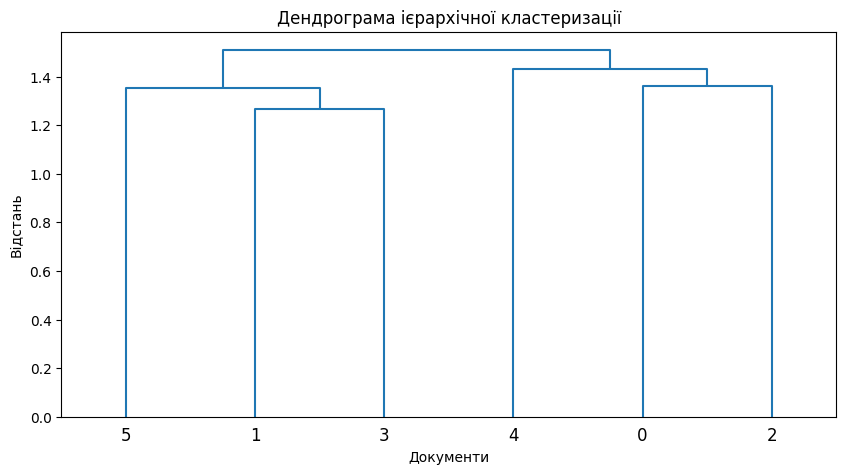

In [13]:
plt.figure(figsize=(10, 5))
linkage_matrix = linkage(tv_matrix, method='ward')
dendrogram(linkage_matrix)
plt.title('Дендрограма ієрархічної кластеризації')
plt.xlabel('Документи')
plt.ylabel('Відстань')
plt.show()

In [14]:
# Word2Vec
from gensim.models import word2vec

wpt = nltk.WordPunctTokenizer()
tokenized_corpus = [wpt.tokenize(document) for document in corpus]

feature_size = 50
window_context = 5
min_word_count = 1
sample = 1e-3

w2v_model = word2vec.Word2Vec(tokenized_corpus,
                              vector_size=feature_size,
                              window=window_context,
                              min_count=min_word_count,
                              sample=sample)

In [15]:
# Вектори слів city та vegetable
words_to_show = ["city", "vegetable"]

for word in words_to_show:
    if word in w2v_model.wv:
        print("Вектор слова " + word + ":")
        print(w2v_model.wv[word])
    else:
        print("Слово", word, "відсутнє у векторному просторі.")

Вектор слова city:
[-0.01724244  0.00733119  0.01038474  0.0115029   0.01492577 -0.01231793
  0.00224083  0.01209443 -0.00567061 -0.01235349 -0.00080666 -0.01674784
 -0.01119122  0.01420857  0.00671369  0.01445358  0.01360097  0.01507267
 -0.00759185 -0.0011391   0.00468679 -0.00902832  0.01677722 -0.01971649
  0.01352884  0.00584819 -0.00986931  0.00879759 -0.0034866   0.01341522
  0.01991792 -0.00874607 -0.00118343 -0.01139434  0.0076943   0.00558197
  0.01378277  0.01220549  0.01908353  0.01854737  0.0158038  -0.01396362
 -0.01833463 -0.00069806 -0.00620541  0.01578082  0.01186912 -0.00309027
  0.00303462  0.00360085]
Вектор слова vegetable:
[ 0.00018913  0.00615464 -0.01362529 -0.00275093  0.01533716  0.01469282
 -0.00734659  0.0052854  -0.01663426  0.01241097 -0.00927464 -0.00632821
  0.01862271  0.00174677  0.01498141 -0.01214813  0.01032101  0.01984565
 -0.01691478 -0.01027138 -0.01412967 -0.0097253  -0.00755713 -0.0170724
  0.01591121 -0.00968788  0.01684723  0.01052514 -0.0131

In [16]:
# Подібні слова до city та vegetable
words_to_check = ["city", "vegetable"]

for word in words_to_check:
    if word in w2v_model.wv:
        print("Слова, схожі на " + word + ":")
        print(w2v_model.wv.most_similar(word))
    else:
        print("Слово", word, "відсутнє у векторному просторі.")

Слова, схожі на city:
[('email', 0.250598281621933), ('soup', 0.2482447624206543), ('name', 0.19950421154499054), ('sea', 0.1962025761604309), ('vegetable', 0.16564932465553284), ('piece', 0.1557765007019043), ('become', 0.1510395109653473), ('grew', 0.14424589276313782), ('frozencut', 0.14417654275894165), ('served', 0.14321765303611755)]
Слова, схожі на vegetable:
[('arrange', 0.19361019134521484), ('city', 0.16564933955669403), ('email', 0.16509075462818146), ('-', 0.15375374257564545), ('soldier', 0.1383683681488037), ('colony', 0.13660678267478943), ('thaw', 0.12744100391864777), ('serving', 0.1248418316245079), ('cup', 0.12147825956344604), ('populated', 0.10721662640571594)]
